In [25]:
import pandas as pd
import matplotlib.pyplot as plt

In [26]:
CSV_FILE = "readings.csv"
OUTPUT_FILE = "battery_plot.svg"
GRAPH_TITLE = "Stupid Battery voltage over time"
X_LABEL = "Elapsed time (hours)"
Y_LABEL = "Voltage (mV)"
LINE_COLOR = "#003087"
LINE_STYLE = "-"
LINE_WIDTH = 1.5
FIGURE_SIZE = (8, 4.5)
TIME_GROUP = "5min"
SHOW_PERCENTAGE = True
PERCENT_Y_LABEL = "Estimated remaining charge (%)"
SHOW_GRID = True
GRID_COLOR = "#707372"
GRID_STYLE = ":"
GRID_WIDTH = 0.5

In [ ]:
readings = pd.read_csv(CSV_FILE)
readings["timestamp"] = pd.to_datetime(readings["timestamp"])
readings = readings.sort_values("timestamp")

smoothed = readings.resample(TIME_GROUP, on="timestamp")["milivolts"].median() # mean affected by outliers
elapsed_hours = (smoothed.index - smoothed.index[0]).total_seconds() / 3600

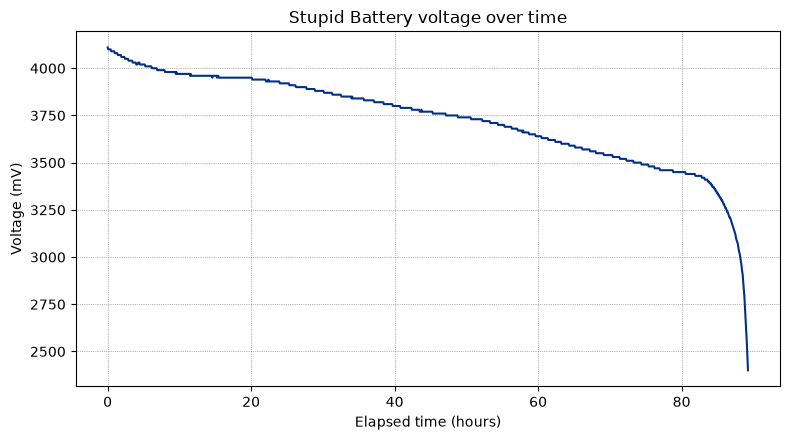

In [ ]:
figure, axes = plt.subplots(figsize=FIGURE_SIZE)


y_values = smoothed
y_label = Y_LABEL

axes.plot(elapsed_hours, y_values, color=LINE_COLOR, linestyle=LINE_STYLE, linewidth=LINE_WIDTH)
axes.set(title=GRAPH_TITLE, xlabel=X_LABEL, ylabel=y_label)

if SHOW_GRID: axes.grid(True, color=GRID_COLOR, linestyle=GRID_STYLE, linewidth=GRID_WIDTH)
figure.tight_layout()


figure.savefig(OUTPUT_FILE)
plt.show()